In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "datasets", "accelerate"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers', 'datasets', 'accelerate'], returncode=0)

In [2]:
import os, json, shutil
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, set_seed)
from datasets import Dataset
import transformers
from google.colab import files
set_seed(42)
MODEL_NAME = "roberta-base"            # lighter option if you are short on disk later: "distilroberta-base"
LABELS = ["negative", "neutral", "positive"]
label2id = {l: i for i, l in enumerate(LABELS)}; id2label = {i: l for l, i in label2id.items()}
print("transformers", transformers.__version__, "| GPU available:", torch.cuda.is_available())

transformers 5.20.2 | GPU available: True


In [3]:
for f in ["autocall_nlp_reviews_dataset.csv", "autocall_nlp_challenge_set.csv"]:
    if not os.path.exists(f):
        print("Select", f); files.upload()
df = pd.read_csv("autocall_nlp_reviews_dataset.csv"); chal = pd.read_csv("autocall_nlp_challenge_set.csv")
df["labels"] = df.label.map(label2id); chal["labels"] = chal.label.map(label2id)
print(df.label.value_counts().to_dict(), "| challenge:", chal.label.value_counts().to_dict())
train_df, tmp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=42)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=42)
print(f"train={len(train_df)} val={len(val_df)} test={len(test_df)}")

Select autocall_nlp_reviews_dataset.csv


Saving autocall_nlp_reviews_dataset.csv to autocall_nlp_reviews_dataset.csv
Select autocall_nlp_challenge_set.csv


Saving autocall_nlp_challenge_set.csv to autocall_nlp_challenge_set.csv
{'negative': 300, 'neutral': 300, 'positive': 300} | challenge: {'positive': 15, 'neutral': 15, 'negative': 15}
train=630 val=135 test=135


In [4]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
lr = LogisticRegression(max_iter=1000).fit(tfidf.fit_transform(train_df.review_text), train_df.labels)
def base_eval(d):
    p = lr.predict(tfidf.transform(d.review_text)); return accuracy_score(d.labels, p), f1_score(d.labels, p, average="macro")
base_test, base_chal = base_eval(test_df), base_eval(chal)
print("Baseline test (acc, macroF1):", np.round(base_test, 4), "| challenge:", np.round(base_chal, 4))

Baseline test (acc, macroF1): [0.9926 0.9926] | challenge: [0.7556 0.7455]


In [7]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
def to_ds(d):
    ds = Dataset.from_pandas(d[["review_text", "labels"]].reset_index(drop=True))
    return ds.map(lambda b: tok(b["review_text"], truncation=True, max_length=128), batched=True, remove_columns=["review_text"])
ds_train, ds_val, ds_test, ds_chal = map(to_ds, [train_df, val_df, test_df, chal])
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=id2label, label2id=label2id)
def compute_metrics(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred), "f1_macro": f1_score(p.label_ids, pred, average="macro")}
import math
EPOCHS, BATCH = 4, 16
WARMUP_STEPS = int(0.1 * math.ceil(len(ds_train) / BATCH) * EPOCHS)   # 10% warm-up; works on old AND new transformers
args = TrainingArguments(output_dir="roberta_out", eval_strategy="epoch", save_strategy="epoch", learning_rate=2e-5,
                         per_device_train_batch_size=BATCH, per_device_eval_batch_size=32, num_train_epochs=EPOCHS,
                         weight_decay=0.01, warmup_steps=WARMUP_STEPS, load_best_model_at_end=True, metric_for_best_model="f1_macro",
                         greater_is_better=True, save_total_limit=1, fp16=torch.cuda.is_available(),
                         report_to="none", seed=42, logging_strategy="epoch")
trainer = Trainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics, processing_class=tok)
trainer.train()

Map:   0%|          | 0/630 [00:00<?, ? examples/s]

Map:   0%|          | 0/135 [00:00<?, ? examples/s]

Map:   0%|          | 0/135 [00:00<?, ? examples/s]

Map:   0%|          | 0/45 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=160, training_loss=0.2621425956487656, metrics={'train_runtime': 100.2308, 'train_samples_per_second': 25.142, 'train_steps_per_second': 1.596, 'total_flos': 67317979040424.0, 'train_loss': 0.2621425956487656, 'epoch': 4.0})

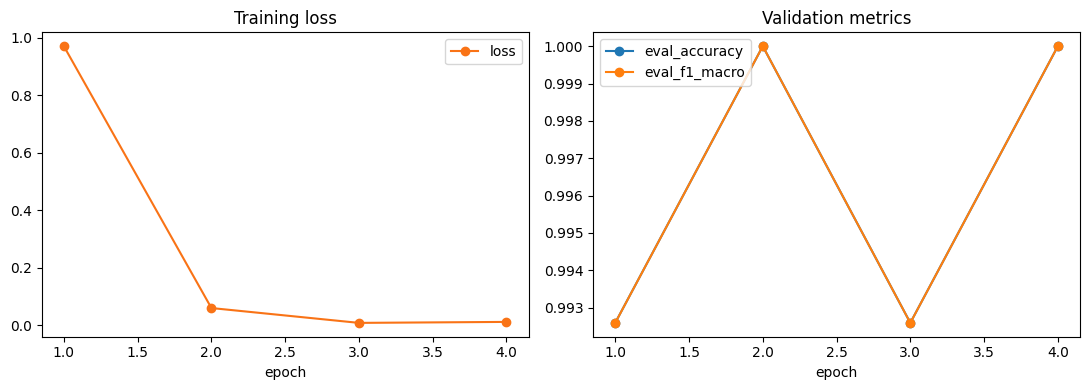

In [8]:
hist = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
hist.dropna(subset=["loss"]).plot(x="epoch", y="loss", ax=ax[0], marker="o", color="#F97316", title="Training loss")
hist.dropna(subset=["eval_f1_macro"]).plot(x="epoch", y=["eval_accuracy", "eval_f1_macro"], ax=ax[1], marker="o", title="Validation metrics")
plt.tight_layout(); plt.savefig("fig_roberta_training.png", dpi=150); plt.show()


===== Test split =====
accuracy=0.9926  macroF1=0.9926
              precision    recall  f1-score   support

    negative      1.000     1.000     1.000        45
     neutral      1.000     0.978     0.989        45
    positive      0.978     1.000     0.989        45

    accuracy                          0.993       135
   macro avg      0.993     0.993     0.993       135
weighted avg      0.993     0.993     0.993       135



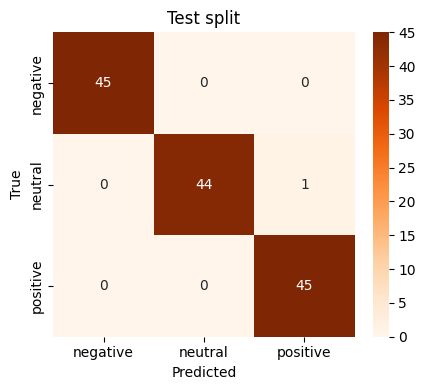


===== Challenge set =====
accuracy=0.8444  macroF1=0.8412
              precision    recall  f1-score   support

    negative      0.824     0.933     0.875        15
     neutral      0.778     0.933     0.848        15
    positive      1.000     0.667     0.800        15

    accuracy                          0.844        45
   macro avg      0.867     0.844     0.841        45
weighted avg      0.867     0.844     0.841        45



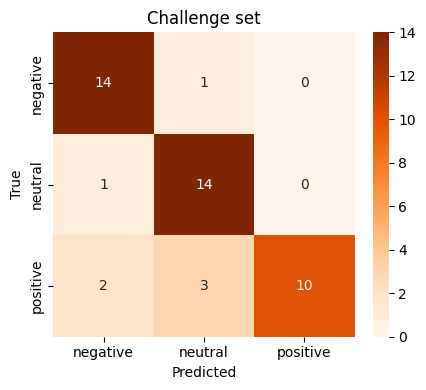

,Test acc,Test macroF1,Challenge acc,Challenge macroF1
TF-IDF + LogReg (baseline),0.9926,0.9926,0.7556,0.7455
roberta-base (fine-tuned),0.9926,0.9926,0.8444,0.8412


In [9]:
def evaluate(ds, name):
    out = trainer.predict(ds); pred = out.predictions.argmax(-1); y = out.label_ids
    print(f"\n===== {name} =====\naccuracy={accuracy_score(y, pred):.4f}  macroF1={f1_score(y, pred, average='macro'):.4f}")
    print(classification_report(y, pred, target_names=LABELS, digits=3, zero_division=0))
    cm = confusion_matrix(y, pred)
    plt.figure(figsize=(4.5, 4)); sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", xticklabels=LABELS, yticklabels=LABELS)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(name); plt.tight_layout()
    plt.savefig(f"fig_cm_{name.split()[0].lower()}.png", dpi=150); plt.show()
    return out, accuracy_score(y, pred), f1_score(y, pred, average="macro")
out_test, acc_t, f1_t = evaluate(ds_test, "Test split")
out_chal, acc_c, f1_c = evaluate(ds_chal, "Challenge set")
cmp = pd.DataFrame({"Test acc": [base_test[0], acc_t], "Test macroF1": [base_test[1], f1_t],
                    "Challenge acc": [base_chal[0], acc_c], "Challenge macroF1": [base_chal[1], f1_c]},
                   index=["TF-IDF + LogReg (baseline)", f"{MODEL_NAME} (fine-tuned)"]).round(4)
display(cmp)

In [10]:
probs = torch.softmax(torch.tensor(out_chal.predictions), dim=-1).numpy()
pred = probs.argmax(1); conf = probs.max(1); true = out_chal.label_ids
flag = (pred == 0) & (conf >= 0.70)
tp = int((flag & (true == 0)).sum()); fp = int((flag & (true != 0)).sum()); fn = int((~flag & (true == 0)).sum())
print(f"flagged={int(flag.sum())}  true-neg flagged={tp}  false alarms={fp}  missed negatives={fn}")
print(f"flag precision={tp/max(tp+fp,1):.3f}  flag recall={tp/max(tp+fn,1):.3f}")

flagged=17  true-neg flagged=14  false alarms=3  missed negatives=1
flag precision=0.824  flag recall=0.933


In [11]:
probs = torch.softmax(torch.tensor(out_chal.predictions), dim=-1).numpy()
pred = probs.argmax(1); conf = probs.max(1); true = out_chal.label_ids
flag = (pred == 0) & (conf >= 0.70)
tp = int((flag & (true == 0)).sum()); fp = int((flag & (true != 0)).sum()); fn = int((~flag & (true == 0)).sum())
print(f"flagged={int(flag.sum())}  true-neg flagged={tp}  false alarms={fp}  missed negatives={fn}")
print(f"flag precision={tp/max(tp+fp,1):.3f}  flag recall={tp/max(tp+fn,1):.3f}")

flagged=17  true-neg flagged=14  false alarms=3  missed negatives=1
flag precision=0.824  flag recall=0.933


In [16]:
os.makedirs("export", exist_ok=True)
trainer.save_model("export/roberta_sentiment"); tok.save_pretrained("export/roberta_sentiment")
json.dump({"base_model": MODEL_NAME, "labels": LABELS, "flag_threshold": 0.70, "test_accuracy": acc_t, "test_macro_f1": f1_t,
           "challenge_accuracy": acc_c, "challenge_macro_f1": f1_c, "baseline_test": list(base_test),
           "baseline_challenge": list(base_chal), "train_size": len(train_df), "val_size": len(val_df), "test_size": len(test_df)},
          open("export/sentiment_info.json", "w"), indent=2)
for f in os.listdir("."):
    if f.startswith("fig_"): shutil.copy(f, "export/")
shutil.make_archive("roberta_export", "zip", "export")
print("Zip size (MB):", round(os.path.getsize("roberta_export.zip") / 1e6))
files.download("roberta_export.zip")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Zip size (MB): 421


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>